# Lesson 13. How a volume leaves a footprint on the screen

[Course plan](../../README.md)

The center is easy. At a depth of 4 m, one meter to the right, an 80-pixel focal length puts it 20 pixels right of the middle. Yet there are other parts of the same cloud on both sides of that center. The nearer part appears larger than the farther one. What width should the entire spot have?

In [1]:
%matplotlib inline
from pathlib import Path
import sys

course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "geometry3d.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import geometry3d as geo
import geometry_demos as demos
np.set_printoptions(precision=4, suppress=True)
lang = "en"

## Two drawings on the same sensor

Orange is the one-scale shell from the last lesson. Each mesh vertex gets a pixel location by dividing by its own depth. The blue ellipse takes a shortcut. We measure how the camera stretches tiny displacements only at the center and apply that stretch to the entire shape. The dark dot is the projected center in both calculations.

With a distant center and a thin shell in depth, the two outlines nearly agree. Bringing the cloud closer or stretching it along $z$ makes the near side of the orange mesh run away. The view angle moves the camera around a fixed shape while keeping the center at $(1,0,z)$ in camera coordinates. The long axis turns relative to the view. During that turn the dark dot stays put.

In [2]:
display(demos.geometry_lab(13, "en"))

## What does the ellipse have to predict?

Consider a small detail on a sloping surface. In space it has a center and a cloud of offsets around that center. The picture still needs a center, but the three spatial scales will turn into two widths and a tilt. One could project the right, lower, and far ends of the three axes and draw around the resulting marks. That gives a sense of scale. The rightmost point in the picture, however, may lie between the axis tips on the ellipsoid. Moving to the right and moving towards the lens reinforce each other. Three isolated tips miss their combined effect.

It helps to separate two jobs for a moment. Ordinary perspective gives the exact answer for the central point. Around that point we can build a little ruler. Its first mark tells us how a pixel moves for a centimeter to the right in space, its second for a centimeter down, and its third for a centimeter in depth. While the cloud stays small, these three marks let us transfer combinations of offsets as well. A larger cloud will show how far from the center the ruler can be trusted.

The shape we are following has a particular weight. The Gaussian reaches one at its center. On its one-scale shell the squared distance in the Gaussian’s own coordinates is one, giving a weight of $e^{-1/2}\approx0.607$. Points inside the shell have higher weights and points outside have lower ones. The blue ellipse in the linear screen model will have the same interpretation. A pencil could outline the contour, but the renderer also needs the gradual change in intensity on both sides of that line.

## How many pixels come from a centimeter?

Horizontally the formula is familiar: $u=100+80x/z$. At center $(1,0,4)$ it gives $u=120$ px. Moving the point 0.01 m right without changing depth gives $100+80\cdot1.01/4=120.2$. The screen shift is 0.2 px, or $0.2/0.01=20$ pixels per meter. A vertical displacement in $y$ leaves the horizontal address alone.

Now let that centimeter go forward along $z$. The result is $100+80/4.01\approx119.950125$ px. A difference of $-0.049875$ px over 0.01 m gives about $-4.9875$ px/m. The minus sign is visible: the farther point moves toward the image center. What happens right at the center as the centimeter shrinks? With step $h$ and focal length $f_x$, subtracting removes the principal point:

$$
\begin{aligned}
\frac{u(z+h)-u(z)}{h}
&=\frac{f_x x}{h}\left(\frac{1}{z+h}-\frac{1}{z}\right)\\
&=\frac{f_x x}{h}\frac{z-(z+h)}{z(z+h)}
=-\frac{f_x x}{z(z+h)}.
\end{aligned}
$$

A common denominator puts $-h$ in the numerator and cancels the nonzero step. As $h$ shrinks, the product in the denominator approaches $z^2$. The local response is $-f_x x/z^2=-80\cdot1/16=-5$ px/m. It is negative for positive $x$, and zero for a point exactly on the axis with $x=0$.

In [3]:
mu = np.array([1., 0., 4.])
focal, principal = 80., (100., 60.)
uv = geo.project_point(mu, focal, principal)
for h in [.1, .01, .001]:
    moved = geo.project_point(mu+[0,0,h], focal, principal)
    print(f"h={h:g} m; Δu/h = {(moved[0]-uv[0])/h:.6f} px/m")

h=0.1 m; Δu/h = -4.878049 px/m
h=0.01 m; Δu/h = -4.987531 px/m
h=0.001 m; Δu/h = -4.998750 px/m


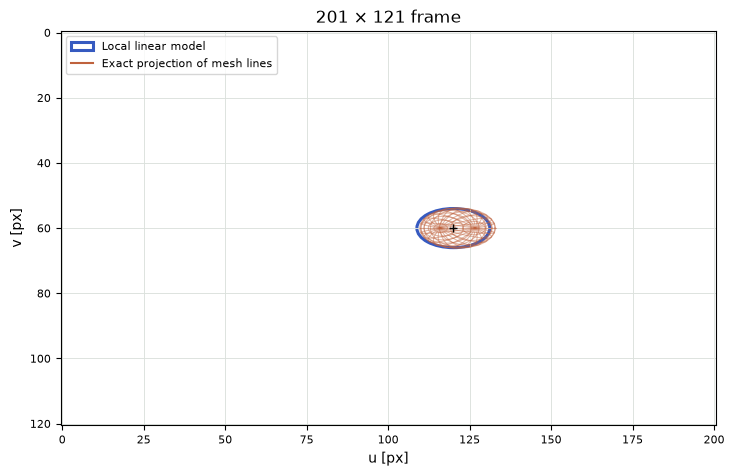

In [4]:
fig = demos.footprint_figure("en")
plt.show()

## Six responses in one table

An image position has two numbers, $u$ and $v$. A spatial displacement has three, $\Delta x,\Delta y,\Delta z$. Each pair of response and cause has a local coefficient. The rows of table $J$ correspond to screen coordinates, the columns to spatial coordinates. This table of partial derivatives is the **Jacobian**. “Partial” means that each column moves just one coordinate at a time.

$$
J=
\begin{bmatrix}
f_x/z & 0 & -f_x x/z^2\\
0 & f_y/z & -f_y y/z^2
\end{bmatrix}
=\begin{bmatrix}20&0&-5\\0&20&0\end{bmatrix}.
$$

Here $y=0$, so moving straight ahead does not change $v$. For a displacement $(0.1,0.05,0.2)$ m, multiplying the first row by the column gives $20\cdot0.1+0\cdot0.05-5\cdot0.2=1$ px. The second row gives $20\cdot0.05=1$ px. Adding the center $(120,60)$ predicts $(121,61)$ px. Exact division for the new point $(1.1,0.05,4.2)$ gives $(120.9524,60.9524)$ px. A smaller displacement leaves a smaller discrepancy.

For a whole meter farther in depth the Jacobian predicts $120-5=115$ px. Exact projection at a depth of 5 m gives $100+80/5=116$ px. A meter **toward** the camera gives a prediction of $120+5=125$ px but an exact result of $100+80/3\approx126.667$ px. A straight line has the same slope on both sides, whereas the slope of perspective division changes along the way.

In [5]:
J = geo.projection_jacobian(mu, focal)
for delta in [[.1,.05,.2],[0,0,1],[0,0,-1]]:
    linear = uv + J @ delta
    exact = geo.project_point(mu+delta, focal, principal)
    print("Δ =", delta, "  linear =", linear, "  exact =", exact)

Δ = [0.1, 0.05, 0.2]   linear = [121.  61.]   exact = [120.9524  60.9524]
Δ = [0, 0, 1]   linear = [115.  60.]   exact = [116.  60.]
Δ = [0, 0, -1]   linear = [125.  60.]   exact = [126.6667  60.    ]


## Depth steps measured against the camera distance

The near point in the preceding numbers gives a larger error than the far point. Where does that asymmetry come from? We keep $x=1$ m, $f_x=80$ px, and the center depth $z=4$ m. Subtracting the two projected positions gives the exact horizontal displacement for a depth step $h$. The third entry in the first row of the Jacobian gives the linear displacement. Both answers are in pixels.

$$
\begin{aligned}
\Delta u_{\rm exact}&=\frac{80}{4+h}-\frac{80}{4}
                      =-\frac{20h}{4+h},\\
\Delta u_{\rm local}&=-5h,\\
\Delta u_{\rm exact}-\Delta u_{\rm local}
 &=\frac{-20h+5h(4+h)}{4+h}=\frac{5h^2}{4+h}.
\end{aligned}
$$

Here $h$ is the numerical step in meters, with $4+h>0$ and the point beyond the near plane. At $+0.4$ m the exact displacement is $-8/4.4\approx-1.818$ px. The linear ruler says $-2$, an error of $0.182$ px. At $-0.4$ m the exact displacement is $8/3.6\approx2.222$ px. The ruler says $2$, an error of $0.222$ px. The numerator of the last line contains the same square in both cases. The denominator gets smaller as the point approaches the camera.

The error looks different when measured against the **displacement itself**. Dividing $0.182/1.818$ gives about a tenth. For the near point, $0.222/2.222$ gives the same fraction. In this experiment at a nonzero step the fraction simplifies to $|h|/4$. A thickness of ten centimeters therefore means something quite different four meters from the lens and twenty centimeters from the lens. This comparison holds for a depth change with $x$ fixed. In other directions two components of motion may reinforce or cancel one another.

## Turning a volume into an ellipse with six numbers

In the initial view the cloud's camera-space covariance is $\Sigma_c=\mathrm{diag}(0.25,0.09,1)$ m². Those values are the squares of the scales $0.5$, $0.3$, $1$ m. On the screen the displacements follow coefficients $J$. The two screen directions transform both sides of the covariance:

$$
\Sigma_2=J\Sigma_c J^{\mathsf T}.
$$

This is the earlier multiplication on both sides, now connecting three input axes to two output axes. We can assemble it by hand. Along $u$, a local $x$ displacement of 0.5 m contributes a scale of $20\cdot0.5=10$ px. One meter along $z$ contributes $-5\cdot1=-5$ px. Independent directions add their **squared** contributions: $10^2+(-5)^2=125$ px². Taking the square root returns a length, $\sqrt{125}\approx11.180$ px. Along $v$ only $y$ contributes: $20\cdot0.3=6$ px, whose square is 36 px².

For a cross term to appear, the same local axis must contribute to both $u$ and $v$. Here $u$ uses $x,z$ while $v$ uses only $y$. Hence the cross term vanishes and the result is $\mathrm{diag}(125,36)$. At zero view angle, changing “Shape rotation” to $45^\circ$ turns the long and short transverse axes together. Their cross covariance is now $(0.25-0.09)/2=0.08$ m². Each screen direction magnifies displacements by a factor of 20. Thus $\Sigma_{uv}=20\cdot0.08\cdot20=32$ px². The blue ellipse leans down to the right. The resulting $2\times2$ matrix and center describe the familiar spot from lesson 4.

What if the original shape is given in the world? Camera orientation $B$ from lesson 10 takes camera axes into the world. The reverse direction, **world to camera**, takes displacements through $W=B^{\mathsf T}$. First comes $\Sigma_c=W\Sigma_w W^{\mathsf T}$, then $J$. Camera translation cancels for differences between nearby points, but stays in the position of the center where $J$ is evaluated. [Kerbl and colleagues' paper](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/) combines these two steps. Keeping them separate here makes it easier to track each matrix's units.

In [6]:
cov3 = geo.covariance_3d([.5,.3,1], [1,0,0,0])
cov2 = geo.projected_covariance(mu, cov3, focal)
print("J =\n", J, "\nΣ₂ =\n", cov2, "\nradii =", np.sqrt(np.diag(cov2)), "px")
np.testing.assert_allclose(cov2, np.diag([125,36]))
tilted = geo.covariance_3d([.5,.3,1], geo.axis_angle_quaternion([0,0,1],45))
np.testing.assert_allclose(geo.projected_covariance(mu, tilted, focal), [[93,32],[32,68]])

J =
 [[20.  0. -5.]
 [ 0. 20. -0.]] 
Σ₂ =
 [[125.   0.]
 [  0.  36.]] 
radii = [11.1803  6.    ] px


Where does the second copy of the Jacobian come from? The covariance of screen offsets $d_u$ and $d_v$ is the average of the products $d_ud_v$ when the offsets are measured from the mean. A symmetric cloud passed through a linear transformation has zero mean offset. Call the rows of the Jacobian $j_u$ and $j_v$. A single spatial displacement $d=(d_x,d_y,d_z)$ gives two numbers, $d_u=j_ud$ and $d_v=j_vd$. Multiplying those numbers pairs every term in the first with every term in the second. For example, one product $d_xd_z$ picks up a factor from column $x$ in the first row and column $z$ in the second. Taking the average replaces each spatial product with the corresponding cell of $\Sigma_c$. That gives the single entry $j_u\Sigma_c j_v^{\mathsf T}$. Pairing the first row with itself instead gives the average square $d_u^2$. The matrix product $J\Sigma_c J^{\mathsf T}$ collects all four row pairings.

## A splat tilted in two planes at once

The diagonal example concealed an interesting part of the calculation. The center now moves to $(1,0.5,4)$ m. Horizontal focal length stays at 80 px, vertical focal length becomes 64 px, and the principal point remains $(100,60)$. The projected center moves to $(100+80/4,\ 60+64\cdot0.5/4)=(120,68)$ px. The Jacobian here has rows $(20,0,-5)$ and $(0,16,-2)$ in pixels per meter. Bringing the point closer now moves it **both** right and down. The second depth coefficient has come to life.

We can build a shape from three independent numbers with mean zero and unit standard deviation. Call them $a,b,c$. Each number acts like a lever. A unit change on the first moves the point by $(0.4,0.2,0)$ m, on the second by $(0,0.3,0.2)$ m, and on the third by $(0,0,0.6)$ m. This construction gives a cloud whose coordinates are correlated. The three arrows can be oblique to one another. The cloud's principal axes then point in different directions from those arrows.

What goes in the covariance row for $x$? Only the first lever changes the horizontal position in space. Its squared spread is $0.4^2=0.16$ m². The same lever changes $y$ by $0.2$ m at the same time, giving an $x,y$ covariance of $0.4\cdot0.2=0.08$ m². The $x$ and $z$ coordinates share no lever, so that entry is zero. The second lever is common to $y$ and $z$, giving $0.3\cdot0.2=0.06$ m². The remaining variances are $0.2^2+0.3^2=0.13$ and $0.2^2+0.6^2=0.40$ m². Independence is precisely what makes products between **different** levers vanish on average.

The resulting table is symmetric. We can recover it as $A A^{\mathsf T}$ with the three original arrows in the columns of $A$. The remaining operations are multiplication on the left by $J$ and on the right by $J^{\mathsf T}$. The first intermediate row takes twenty copies of the first covariance row and subtracts five copies of the third. Entry one becomes $20\cdot0.16-5\cdot0=3.2$, entry two becomes $20\cdot0.08-5\cdot0.06=1.3$, and entry three gives $20\cdot0-5\cdot0.40=-2$. The second row instead takes sixteen copies for $y$ and minus two for $z$.

$$
\begin{aligned}
J\Sigma_c&=
\begin{bmatrix}3.2&1.3&-2\\1.28&1.96&0.16\end{bmatrix},\\
S_{uu}&=3.2\cdot20+1.3\cdot0+(-2)(-5)=74,\\
S_{uv}&=3.2\cdot0+1.3\cdot16+(-2)(-2)=24.8,\\
S_{vv}&=1.28\cdot0+1.96\cdot16+0.16(-2)=31.04.
\end{aligned}
$$

The intermediate table had units of pixels times meters. The last multiplication by pixels per meter leaves squared pixels. Row two, column one gives $1.28\cdot20+0.16(-5)=24.8$. Equality of the two cross terms is a check on the arithmetic and on the transpose. Repeating the calculation as though $x,y,z$ were independent would produce plausible-looking numbers. The tilt of the footprint and the weights of particular pixels would be wrong.

In [7]:
point = np.array([1., .5, 4.])
j = geo.projection_jacobian(point, (80, 64))
arrows = np.array([[.4, 0, 0], [.2, .3, 0], [0, .2, .6]])
sigma = arrows @ arrows.T
screen = geo.projected_covariance(point, sigma, (80, 64))
print("Σc =\n", sigma, "\nJ Σc =\n", j @ sigma, "\nS =\n", screen)
np.testing.assert_allclose(screen, [[74, 24.8], [24.8, 31.04]])
np.testing.assert_allclose(screen, (j @ arrows) @ (j @ arrows).T)

Σc =
 [[0.16 0.08 0.  ]
 [0.08 0.13 0.06]
 [0.   0.06 0.4 ]] 
J Σc =
 [[ 3.2   1.3  -2.  ]
 [ 1.28  1.96  0.16]] 
S =
 [[74.   24.8 ]
 [24.8  31.04]]


## Two pixels at the same distance

One pixel is six columns to the right of the center and four rows below it. Another is six columns to the right and four rows above. A ruler on the sensor gives $\sqrt{6^2+4^2}=\sqrt{52}$ px to both. On the tilted splat, one pixel lies roughly along the long axis while the other lies across it. We can check our interpretation of the matrix by predicting which mark will carry more weight before drawing the image.

Write the offset as $\delta=(d_u,d_v)$. A two-row matrix has a short inversion recipe. The diagonal entries exchange places, the two cross entries change sign, and the entire result is divided by the determinant. Here the determinant is $74\cdot31.04-24.8^2=1681.92$ px⁴. The numerator in the top corner still has $31.04$ px², so each resulting entry has units of inverse squared pixels. The planar Gaussian from earlier lessons can now accept actual sensor addresses.

$$
q=\delta^{\mathsf T}S^{-1}\delta
=\frac{31.04d_u^2-2\cdot24.8d_ud_v+74d_v^2}{1681.92}.
$$

The factor of two has a visible origin. The product $d_ud_v$ comes once from the upper row and once from the lower row. At pixel $(126,72)$ the product is positive, and the subtraction brings $q$ down to $0.661$. The weight is $e^{-0.661/2}\approx0.719$. At $(126,64)$ only the sign of the vertical offset changes. This gives $q\approx2.076$ and a weight of $0.354$. The same ruler distance has produced almost a factor of two in weight. Removing the cross term from the covariance would give the two marks equal weights. The second panel shows what that omission does to the picture.

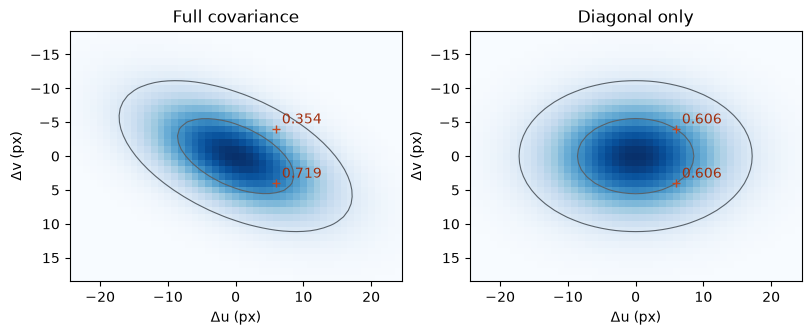

In [8]:
du, dv = np.meshgrid(np.arange(-24, 25), np.arange(-18, 19))
offsets = np.stack([du, dv], axis=-1)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6), layout="constrained")
titles = ("Полная ковариация", "Только диагональ") if lang == "ru" else ("Full covariance", "Diagonal only")
for ax, s, title in zip(axes, [screen, np.diag(np.diag(screen))], titles):
    q = np.einsum("...i,ij,...j->...", offsets, np.linalg.inv(s), offsets)
    weights = np.exp(-q / 2)
    ax.imshow(weights, extent=[-24.5, 24.5, 18.5, -18.5], cmap="Blues", vmin=0, vmax=1)
    ax.contour(du, dv, q, levels=[1, 4], colors="#59626a", linewidths=.8)
    for v in [4, -4]:
        weight = weights[v + 18, 6 + 24]
        ax.plot(6, v, marker="+", color="#c54821")
        ax.annotate(f"{weight:.3f}", (6, v), xytext=(4, 4), textcoords="offset points", color="#a22e0d")
    ax.set(title=title, xlabel="Δu (px)", ylabel="Δv (px)", aspect="equal")
plt.show()

## Where the blue curve falls behind

The near plane in the experiment lies at 0.2 m. Suppose the center has $z=2$ and the depth scale is 1.5 m. The shell's nearest tip lies at $2-1.5=0.5$ m. Even that tip is still in front of the camera, but dividing by 0.5 or by 2 now gives very different answers. Only the part of the orange mesh that falls inside the frame appears in the drawing.

Lowering center depth to 1 m at the same scale brings part of the shell across the near plane. Those points are excluded from the orange mesh. The center still has a Jacobian and we can draw the blue ellipse. Having enough numbers to draw it is easier than getting an accurate outline. The Gaussian itself also has infinite tails. This experiment compares the chosen $D^2=1$ shell, as distinct from a light integral along a ray or the exact projection of the entire density.

**An experiment.** The center moves onto the optical axis at $(0,0,4)$. Does doubling only $s_z$ change the blue ellipse if the principal axes line up with the camera?

<details>
<summary>Working it out</summary>

Both depth coefficients vanish: $-80\cdot0/16=0$. Inside the linear model the $s_z$ contribution disappears. The radii are $20\cdot0.5=10$ and $20\cdot0.3=6$ px. The orange mesh still changes as it thickens, because its off-center points each have their own $x,y,z$.

</details>

**Estimating error.** How far off is the horizontal prediction for a point 0.5 m nearer than the original center $(1,0,4)$?

<details>
<summary>Working it out</summary>

The step is $\Delta z=-0.5$. The Jacobian predicts $120+(-5)(-0.5)=122.5$ px. Exact division gives $100+80/3.5\approx122.857$ px. The difference is about 0.357 px. The next scene will contain several such footprints and introduce the question of which one contributes to a pixel first.

</details>

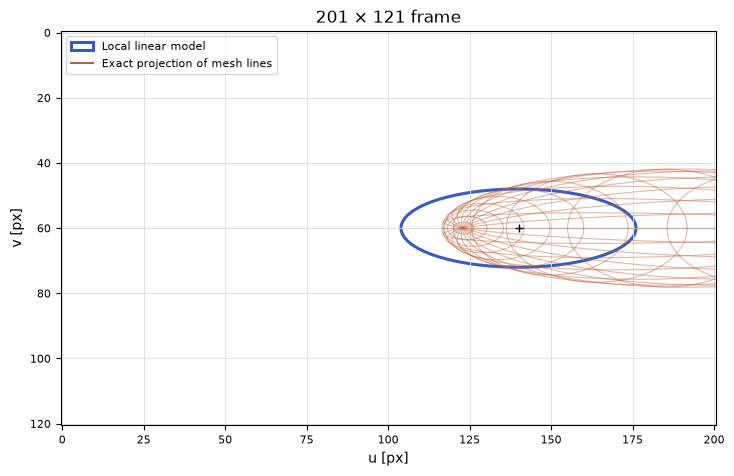

In [9]:
fig = demos.footprint_figure("en", depth=2, sz=1.5)
plt.show()

## Two more ways to catch a rendering mistake

**A tighter lens or a bigger picture?** Both focal lengths in the asymmetric example double, while the principal point and resolution stay unchanged. What happens to the center, radii, and covariance? Does the weight six pixels right and four down stay the same?

<details>
<summary>Worked answer</summary>

The shift from the principal point used to be $(20,8)$ and becomes $(40,16)$. The new center is $(140,76)$. Each Jacobian row gains a factor of two. The covariance gains $2^2=4$ while the axis lengths double. A pixel at the old offset is now closer to the peak in units of splat scale. Its $q$ falls by a factor of four and its weight rises from $0.719$ to $e^{-0.661/8}\approx0.921$. The old weight now occurs at offset $(12,8)$. The narrower field of view adds no detail to the cloud itself.

</details>

**The same shape in another part of the frame.** The center moves to the optical axis while the orientation and original oblique covariance stay fixed. Will the tilt disappear from the blue footprint?

<details>
<summary>Worked answer</summary>

The new center has $x=y=0$, so the two depth sensitivities disappear. The rows reduce to $(20,0,0)$ and $(0,16,0)$. But $x$ and $y$ still share the first lever in space. Their cross term becomes $20\cdot0.08\cdot16=25.6$ px². The diagonal becomes $(64,33.28)$ px². The tilt survives. Both the shape of an object and the part of the sensor where it lands can contribute to one visible tilt.

</details>